## Intermediate Data Science

## Important Information

- Email: [joanna_bieri@redlands.edu](mailto:joanna_bieri@redlands.edu)
- Office Hours take place in Duke 209 - [Office Hours Schedule](https://joannabieri.com/schedule.html)
- [Class Website](https://joannabieri.com/data201_intermediate.html)
- [Syllabus](https://joannabieri.com/data201/IntermediateDataScience.pdf)

## Today's Reading

*Introduction to Machine Learning with Python*, Chapters 2.3.1 to 2.3.3 - Some Sample Datasets, k-Nearest Neighbors, and Linear Models.

## Career Reading

*Build a Career in Data Science*, 4.1 and 4.3 Building a Portfolio. Read it and take notes. We discuss portfolios, resumes and cover letters together on Tuesday 11/17.

## Final Project

Your **Project Proposal and Exploratory Data Analysis** is due **Tuesday 11/10 at 11:59pm**. It is individual work, on Canvas and in your sandbox. See the [Final Project Information](https://joannabieri.com/data201/FinalProjectInfo.html) page.

## Spring Classes

Don't forget to sign up for Spring classes: DATA 211!

---------------------------------------

## Supervised vs. Unsupervised

So far in this class we have talked about three basic machine learning techniques:

- K-Nearest Neighbors (KNN) - we predict the class that a new observation belongs to by considering its nearest neighbors.
- Linear Regression - we predict a continuous numerical value based on a linear fit. For a nonlinear fit we let our parameters use polynomial features.
- Logistic Regression - we predict the class of a new observation based on assuming a linear fit for the log odds and solve for a probability.

All of these are supervised methods.

### Supervised

In supervised learning you have a **labeled** data set, meaning that you have some examples of what the answers are. Each observation has a known output (or target).

Examples:

- Predicting house prices based on a bunch of observations where you have house prices for each of those observation.
- Recognizing pictures of dogs and cats when you have a bunch of photos where someone has labeled the photos as dog or cat.

In supervised learning you are learning a mapping from the inputs (variables) to the outputs (targets).

### Unsupervised

In unsupervised learning you have an **unlabeled** data set, meaning that you only have features or variables. You are trying to learn some underlying structure or patterns within the data.

Examples:

- Trying to learn how to segment (cluster) customers based on variables like purchases, likes, views. In this case you don't know what the groups are or even how many groups there are - you are hoping to figure out which customers are similar.
- You have a large many dimensional data set and you are trying to understand which features are most important. You might do an unsupervised dimensionality reduction.

In unsupervised learning you are learning patterns in the data from only the inputs (variables). You do not know the labels.

## Continue with Supervised Learning

Today we will do a deeper dive into ways to make different or better predictions with KNN and Linear Regression. We will talk more about over and underfitting. This should build on what we did last class! In the second half we will talk about **scaling** your data and **regularization**. Both of these can really help our linear models!

In [1]:
# NOTE - This list of package imports is getting long
# In a professional setting you would only want to
#      import what you need!

# Some basic package imports
import os
import numpy as np
import pandas as pd

# Visualization packages
import matplotlib.pyplot as plt
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.io as pio
pio.renderers.default = 'notebook_connected'
import seaborn as sns

# ML packages
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, precision_score, recall_score
from sklearn.metrics import confusion_matrix, classification_report

## K-Nearest Neighbors (KNN)

K-Nearest Neighbors is a supervised learning algorithm that is based on the idea that similar data points exist close to each other in feature space. We have seen how we can use KNN for classification, but it can be used for both classification and regression.

## Intuition

Imagine you have a set of labeled data points plotted in space.
To predict the label of a **new, unlabeled point**, KNN looks at the **K closest points** (its *neighbors*) and assigns the most common label among them.

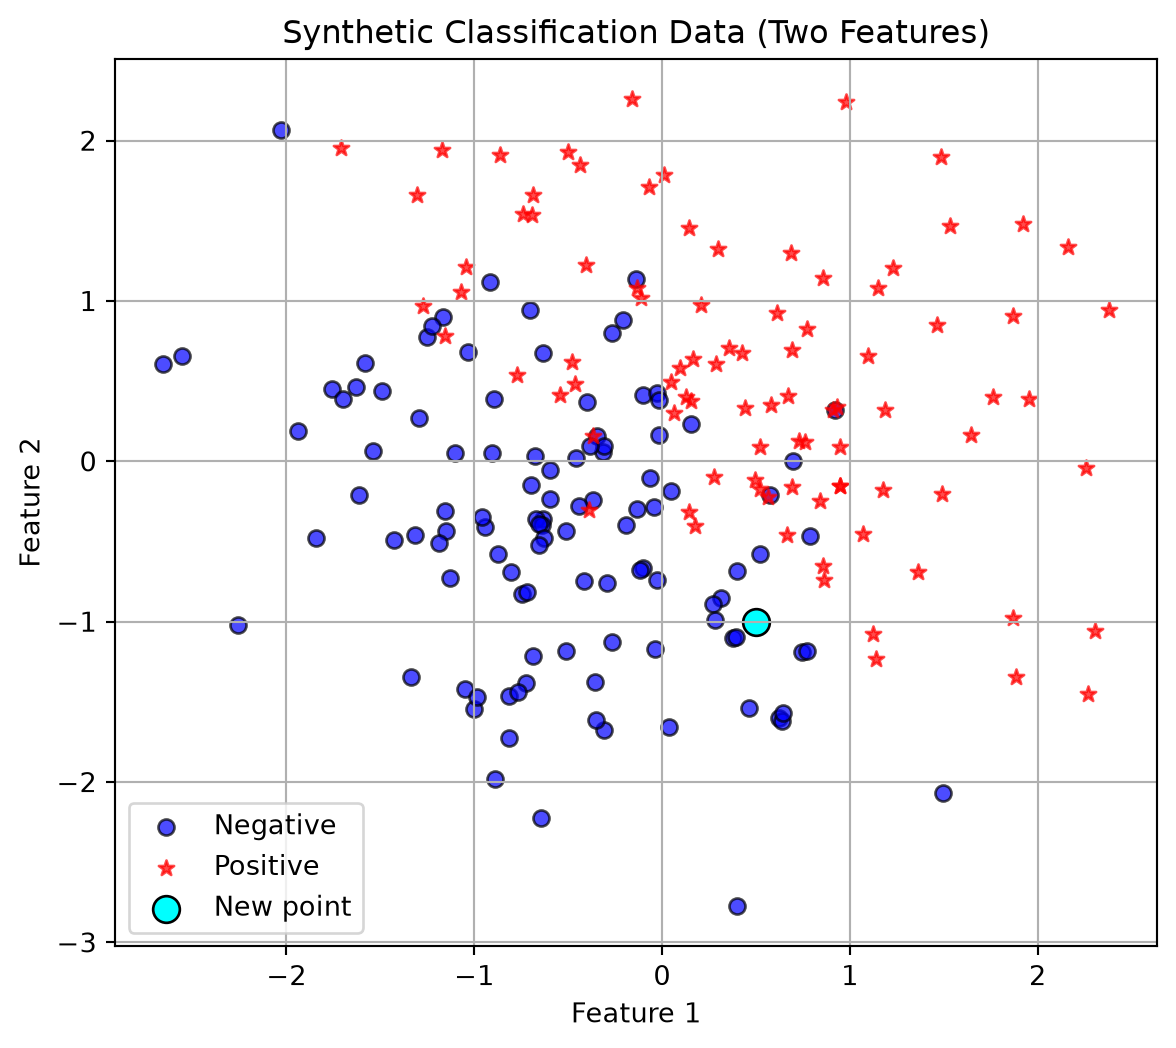

In [2]:
# Generate synthetic binary classification data
np.random.seed(0)
n_samples = 200
X1 = np.random.randn(n_samples, 2)
y1 = (X1[:,0] + X1[:,1] + 0.5 * np.random.randn(n_samples) > 0).astype(int)

new_point = np.array([[0.5, -1.0]])

# Scatter plot
plt.figure(figsize=(7,6))
plt.scatter(X1[y1==0, 0], X1[y1==0, 1], 
            color='blue', alpha=0.7, 
            label='Negative', edgecolor='k')
plt.scatter(X1[y1==1, 0], X1[y1==1, 1], 
            color='red', alpha=0.7, marker='*', label='Positive')
plt.scatter(new_point[0, 0], new_point[0, 1], 
            color='cyan', s=100, 
            label='New point', edgecolor='k')
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Classification Data (Two Features)")
plt.legend()
plt.grid(True)
plt.show()

## Training Data

In this case the training data is existing data points with any number of features. In the picture above we have two features so we can plot the data points in 2-dimensions. Now given a new points we do the following algorithm.

## Algorithm Steps

1. Choose a value for **K** (the number of neighbors to consider).
2. Calculate the **distance** between the new data point and all training points  
   (commonly using *Euclidean distance*).
3. Select the **K nearest neighbors** based on smallest distances.
4. For **classification**:
   - Take a **majority vote** of the neighbors’ classes.
   For **regression**:
   - Take the **average** of the neighbors’ target values.
5. Return the predicted label or value.

So in the picture above, lets say we choose $K=3$, then we would look at the three nearest neighbors, euclidean distance as the crow flies, and see that hey are all dark blue circles. So we would classify our new point as a negative!

## Distance Formula

For two data points $ x = (x_1, x_2, \ldots, x_n) $ and $ y = (y_1, y_2, \ldots, y_n) $:

$$
d(x, y) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}
$$

## Code

In our first Introduction to ML class we had the following code:

In [3]:
random_seed = 42
X_train, X_test, y_train, y_test = train_test_split(X1,
                                                    y1, 
                                                    test_size=0.20, 
                                                    random_state=random_seed)

In [4]:
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [5]:
knn.score(X_test, y_test)

0.825

## Is this a good fit?

Well we got 82% accuracy using $k=1$ neighbor and this sounds okay, but often we want more information! Two ways we will consider if our model is good.

1. If we are in two dimensions we can visualize the decision boundary! This will not work for higher dimensional data! How does the decision boundary change as we increase the number of neighbors?

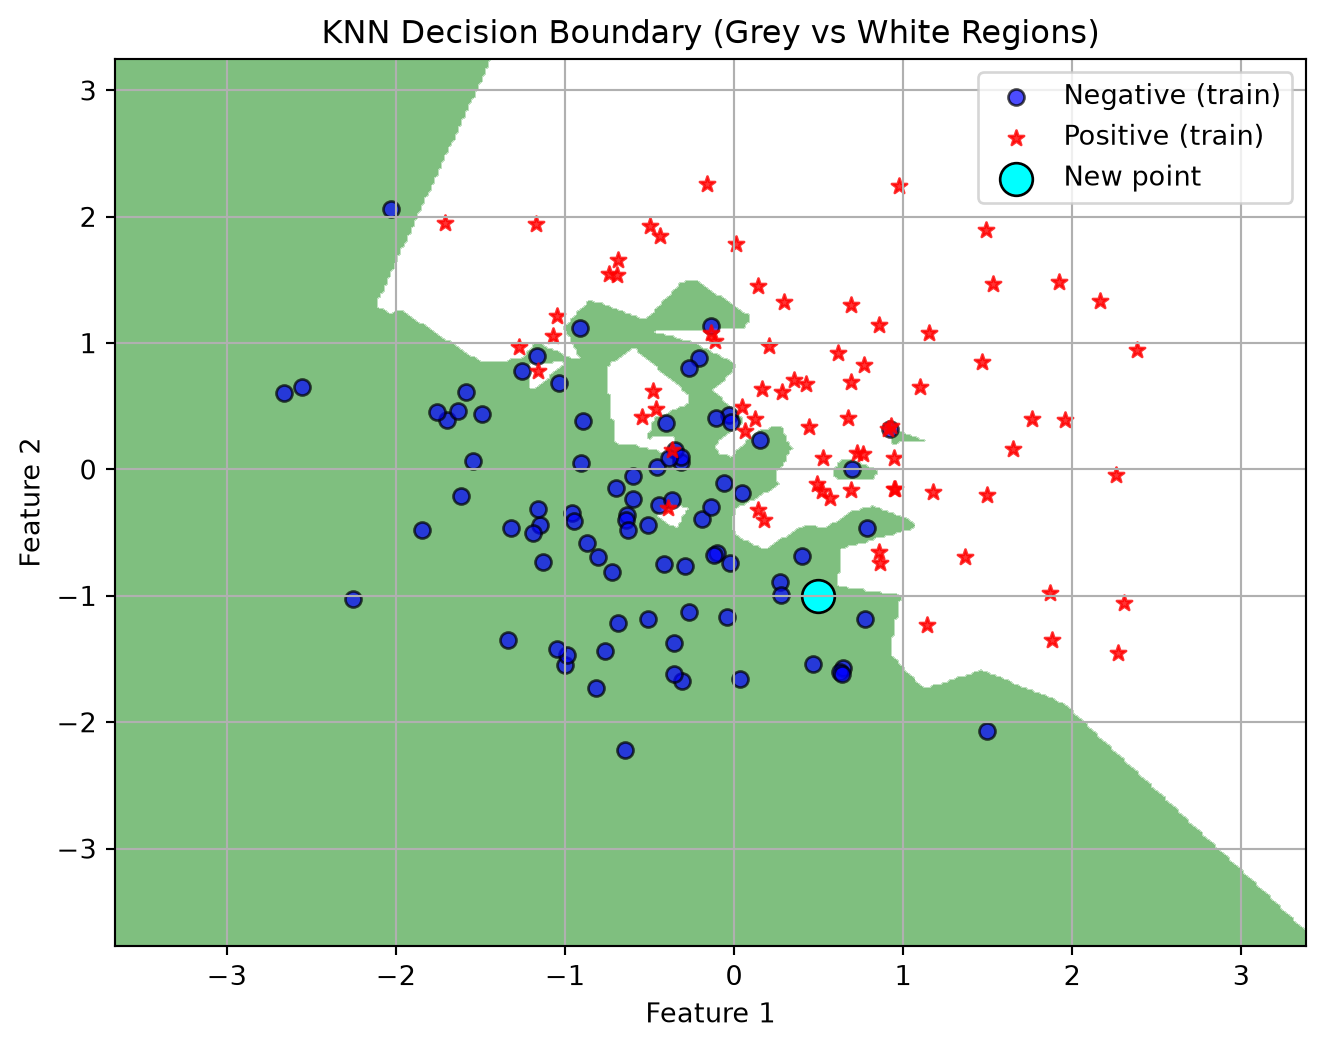

In [6]:
# --- Create mesh grid for decision boundary ---
h = 0.02  # grid step size
x_min, x_max = X1[:, 0].min() - 1, X1[:, 0].max() + 1
y_min, y_max = X1[:, 1].min() - 1, X1[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

# Predict class for each grid point
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundary with grey and white shading
plt.figure(figsize=(8,6))
plt.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], 
             colors=['green', 'white'], alpha=0.5)

# Plot the training data
plt.scatter(X_train[y_train==0, 0], X_train[y_train==0, 1], 
            color='blue', alpha=0.7, edgecolor='k', label='Negative (train)')
plt.scatter(X_train[y_train==1, 0], X_train[y_train==1, 1], 
            color='red', alpha=0.8, marker='*', label='Positive (train)')

# Plot the new point
plt.scatter(new_point[0, 0], new_point[0, 1], 
            color='cyan', s=150, edgecolor='k', label='New point')

plt.title("KNN Decision Boundary (Grey vs White Regions)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

2. We can output information about the confusion matrix and classification report. This works even with higher dimensional data. Always a good idea to check out these numbers. How do they change as we increase $k$?

In [7]:
y_pred = knn.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print(f"Accuracy on test set: {acc:.3f}")

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy on test set: 0.825
Confusion Matrix:
[[21  3]
 [ 4 12]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.88      0.86        24
           1       0.80      0.75      0.77        16

    accuracy                           0.82        40
   macro avg       0.82      0.81      0.82        40
weighted avg       0.82      0.82      0.82        40



## You Try - Warm-Up 1

Make changes to the number of neighbors in the code above. How does changing the value of $k$ (the number of neighbors) change the decision boundary?

Does a lower value of $k$ seem to overfit or underfit the data? How do you know?

In [8]:
# Your code here

## Hyperparameter Tuning

A big question that comes out of our KNN model is: How many neighbors should we choose? This is where doing a systematic test is really helpful! 

## Plotting Training and Testing Accuracy

One great way to visualize how well you are doing with a task is to plot how the accuracy (or error in some cases) changes on BOTH the training and testing set as you change a parameter. 

- You want your model to do well on BOTH the training and testing set.
- Underfitting is when your model does not do particularly well on either the testing or training set. Usually when you have not trained enough or when you have picked a model that is too simple for the task. Think straight line fits for curved data or really unreliable decision boundaries.
- Overfitting is when your model does really well on the training set but not very well on the testing set. This means your model is memorizing the training data and will not generalize well to new data. Typically happens when you train too much or when you have picked a model that is too complicated for the task. Think really curvy fits that go through almost every point or decision boundaries with lots of jagged edges.

## Example of exploring Hyperparameters

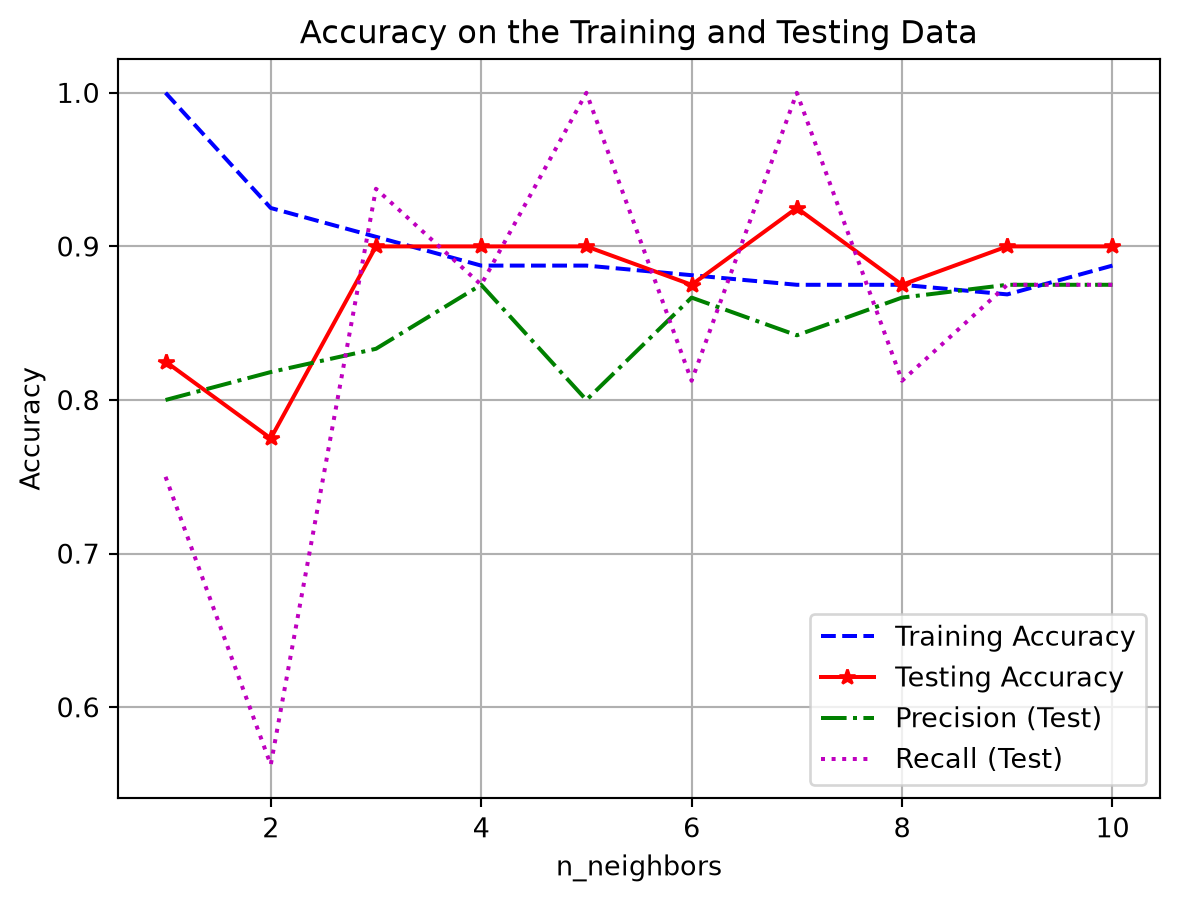

In [9]:
#1 Choose a range for your hyperparameters
k_vals = [1,2,3,4,5,6,7,8,9,10]

#2 Loop through the parameters and retrain your model
#     IMPORTANT - I do not redo the test train split!
#                 Do the split only once.

# An empty list for collecting the accuracy numbers
acc_train = []
acc_test = []
prec_test = []
rec_test = []
for k in k_vals:
    # Train the model with k-neighbors
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    # Get the accuracy on training data
    y_pred_train = knn.predict(X_train)
    acc_train.append(accuracy_score(y_train,y_pred_train))

    # Get the accuracy on testing data
    y_pred_test = knn.predict(X_test)
    # Add the accuracy to the list
    acc_test.append(accuracy_score(y_test, y_pred_test))
    prec_test.append(precision_score(y_test, y_pred_test))
    rec_test.append(recall_score(y_test, y_pred_test))

# 2 Plot the results

plt.plot(k_vals,acc_train,'--b',label='Training Accuracy')
plt.plot(k_vals,acc_test,'-*r',label='Testing Accuracy')
plt.plot(k_vals, prec_test, '-.g', label='Precision (Test)')
plt.plot(k_vals, rec_test, ':m', label='Recall (Test)')
plt.grid()
plt.legend()
plt.title('Accuracy on the Training and Testing Data')
plt.xlabel('n_neighbors')
plt.ylabel('Accuracy')
plt.show()

The **best** number of neighbors is probably somewhere in the middle. Depending on what is most important for your given application. Do you need high precision or recall? Is accuracy most important?


## KNN Regression

We can use KNN for regression tasks too! It works the same way, except instead of having the neighbors vote on what class the new point should belong to, you take an average of the neighbors values.

Here is regression data - remember in regression we are trying to predict a continuous numerical outcome.

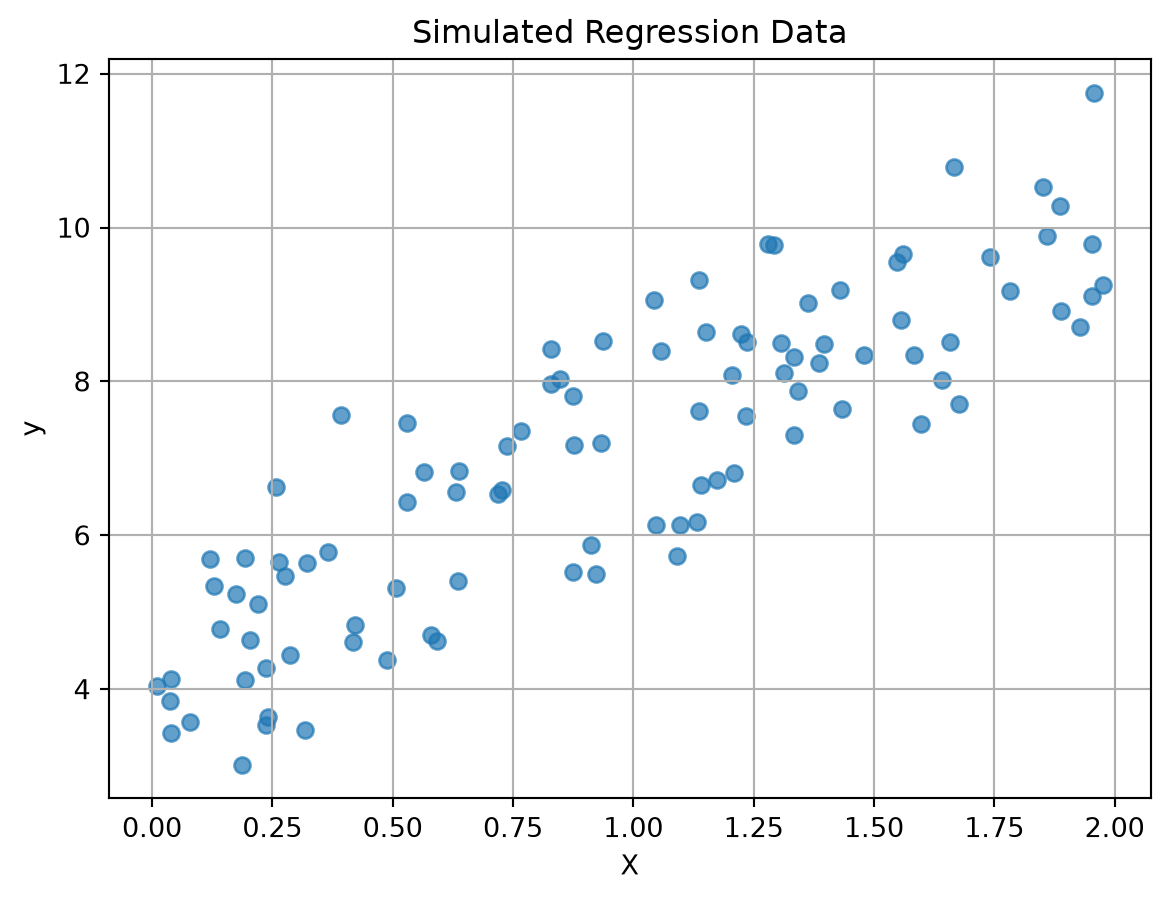

In [10]:
# Generate a synthetic dataset
np.random.seed(0)
n_samples = 100
X = 2.0 * np.random.rand(n_samples, 1)
y = 4.0 + 3.0 * X[:,0] + np.random.randn(n_samples)

plt.scatter(X, y, alpha=0.7)
plt.title("Simulated Regression Data")
plt.xlabel("X")
plt.ylabel("y")
plt.grid()
plt.show()

Last time we did a linear regression of this data, let's see what KNN does with this data and compare the two models!

In [11]:
# Split into train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Make a line for looking at the model outputs
X_line = np.linspace(0, 2, 100).reshape(-1, 1)

In [12]:
# Linear Regression
linreg = LinearRegression()
linreg.fit(X_train, y_train)

# --- Get predictions and line ---
y_pred_linreg = linreg.predict(X_test)
y_pred_line_linreg = linreg.predict(X_line)

# Get the metrics
mse = mean_squared_error(y_test, y_pred_linreg)
r2 = r2_score(y_test, y_pred_linreg)
print(f"MSE on test set: {mse:.3f}")
print(f"R² on test set: {r2:.3f}")

MSE on test set: 0.918
R² on test set: 0.652


In [13]:
# A new package: KNeighborsRegressor (we imported it at the top)

# KNN Regression
k=1
knn_reg = KNeighborsRegressor(n_neighbors=k)
knn_reg.fit(X_train, y_train)

# --- Get predictions and line ---
y_pred_knn = knn_reg.predict(X_test)
y_pred_line_knn = knn_reg.predict(X_line)

mse = mean_squared_error(y_test, y_pred_knn)
r2 = r2_score(y_test, y_pred_knn)
print(f"MSE on test set: {mse:.3f}")
print(f"R² on test set: {r2:.3f}")

MSE on test set: 1.306
R² on test set: 0.505


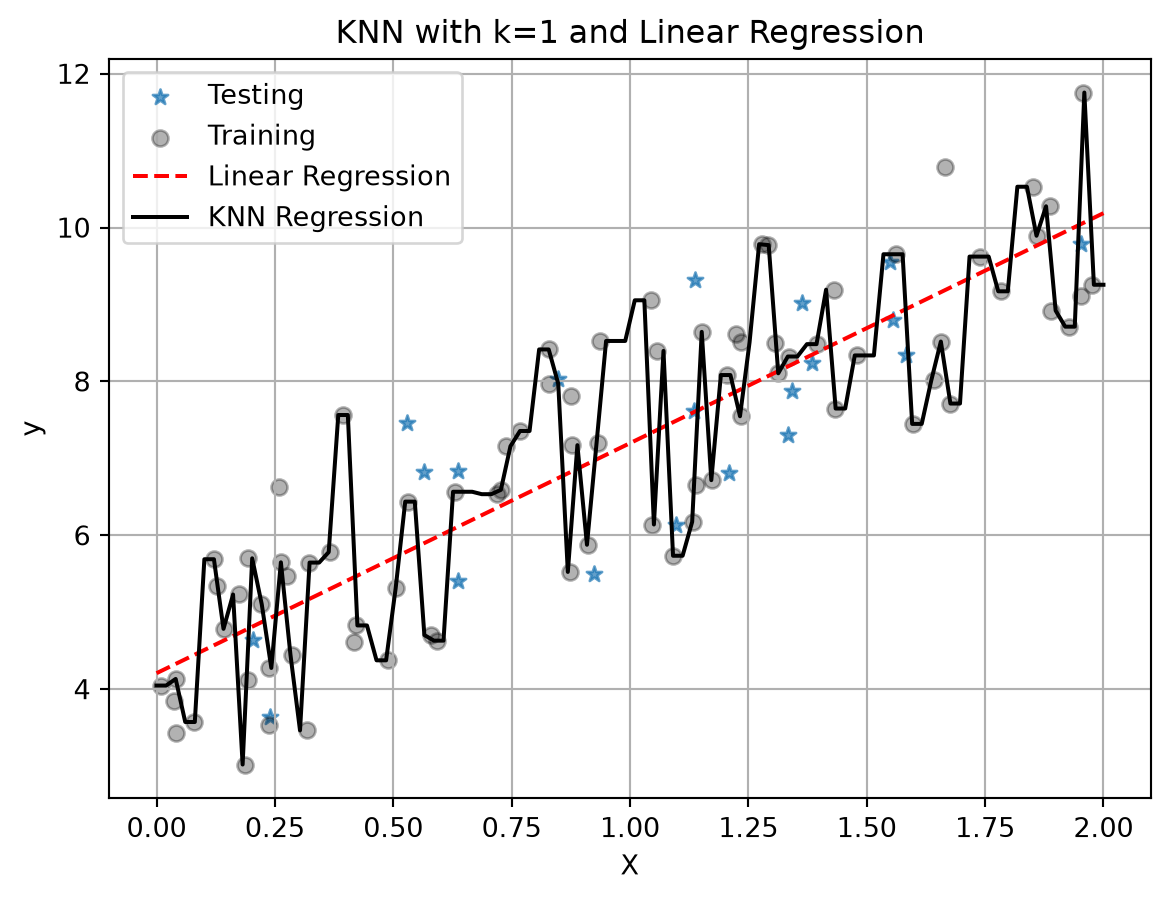

In [14]:
plt.scatter(X_test, y_test, marker='*', alpha=0.7,label='Testing')
plt.scatter(X_train,y_train, color='black', alpha=0.3,label='Training')
plt.plot(X_line,y_pred_line_linreg,'r--',label='Linear Regression')
plt.plot(X_line,y_pred_line_knn,'k-',label='KNN Regression')
plt.title(f"KNN with k={k} and Linear Regression")
plt.xlabel("X")
plt.ylabel("y")
plt.grid()
plt.legend()
plt.show()

With only one neighbor, KNN just fits a line between all the points and we see that it has worse metrics: higher MSE and lower $R^2$. But remember we chose $k=1$ here and it is our job to pick a good value for $k$. It might also be that linear regression is the better model. Again, it is our job to figure this out for our data set and application!


## You Try - Warm-Up 2

What happens as K is increased?

For regression, does a lower value of $k$ seem to overfit or underfit the data? How do you know?

In [15]:
# Your code here

---------------------------------------

# Part 2 - Scaling and Regularization

So far our examples had one or two features. What happens when we have a lot of features? Let's load a data set with 50 features and try a plain linear regression.

## Train a Model on Demo Data

Here we will see a model that does quite well on a training set, but not as well on the testing set. Where we seem to overfit even with a very simple model.

In [16]:
file = 'https://joannabieri.com/data201/data/linear_reg_demo.csv'
df = pd.read_csv(file)
df

,X0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X41,X42,X43,X44,X45,X46,X47,X48,X49,y
0,-1.342024,2.644872,2.731009,-2.643724,-0.356181,2.350662,-2.951172,2.328301,4.066488,4.538268,...,3.252113,-2.410185,1.117097,0.171368,0.698699,-1.203474,0.293631,-3.224743,-2.638178,2.068888
1,-0.962461,-0.885964,3.331960,-0.899836,-2.657224,0.611735,2.106507,4.374248,2.113490,0.520471,...,1.735759,-0.550186,-1.157524,2.982892,0.215629,-1.582387,-3.858339,0.687370,0.170460,14.604536
2,0.424560,0.416815,0.111514,0.421216,1.493705,-0.196899,-0.610448,0.003991,0.306564,0.767867,...,0.328082,-0.342343,0.460536,-0.361867,-0.354331,0.109588,0.622223,-0.275862,-0.385733,-2.161666
3,-0.531133,-3.208629,1.084534,2.353597,0.007463,-3.221481,-0.728961,1.523102,-0.455153,-2.709579,...,1.971500,-2.350100,2.846246,3.816032,-0.863181,-0.675704,0.146581,1.776943,0.878032,5.124691
4,0.411236,1.247723,-0.041707,1.247229,3.315608,-1.163993,-0.769326,0.372504,0.402942,2.628126,...,-0.135925,-1.825401,3.072627,-0.973546,-0.484639,0.339584,1.220820,-0.253012,-1.032695,-7.629544
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,-0.434508,0.097347,-1.353913,-0.207688,-1.210280,0.125185,1.282331,-0.784026,-1.352825,-0.337206,...,-2.098063,0.644308,0.174951,-1.056514,0.819055,0.494306,-0.587877,0.479324,0.521405,-4.015535
196,-2.851576,4.059801,1.523292,-5.085669,-2.971662,3.915679,-3.495266,1.038668,3.826526,5.511904,...,1.534703,-2.427997,1.894649,-1.491945,2.542125,-1.074327,0.463561,-4.676907,-3.010609,-1.711600
197,1.199517,-0.345678,1.260737,2.137194,1.652054,-1.654168,5.736806,3.802432,-0.385061,1.452547,...,-1.948709,0.467006,-0.193887,0.559777,-0.762078,-0.091667,-4.458026,3.310913,1.052443,5.045598
198,-0.305365,-1.346562,1.750246,-0.301057,-2.059367,0.317157,1.114768,2.042436,0.857123,-1.329480,...,1.434269,0.300923,-1.778999,2.292379,-0.281260,-0.972267,-2.150849,0.665495,0.416339,10.176725


In [17]:
df.shape

(200, 51)

In [18]:
df.keys()

Index(['X0', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10',
       'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20',
       'X21', 'X22', 'X23', 'X24', 'X25', 'X26', 'X27', 'X28', 'X29', 'X30',
       'X31', 'X32', 'X33', 'X34', 'X35', 'X36', 'X37', 'X38', 'X39', 'X40',
       'X41', 'X42', 'X43', 'X44', 'X45', 'X46', 'X47', 'X48', 'X49', 'y'],
      dtype='str')

In [19]:
x_cols = ['X0', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10',
       'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20',
       'X21', 'X22', 'X23', 'X24', 'X25', 'X26', 'X27', 'X28', 'X29', 'X30',
       'X31', 'X32', 'X33', 'X34', 'X35', 'X36', 'X37', 'X38', 'X39', 'X40',
       'X41', 'X42', 'X43', 'X44', 'X45', 'X46', 'X47', 'X48', 'X49']
y_cols = ['y']

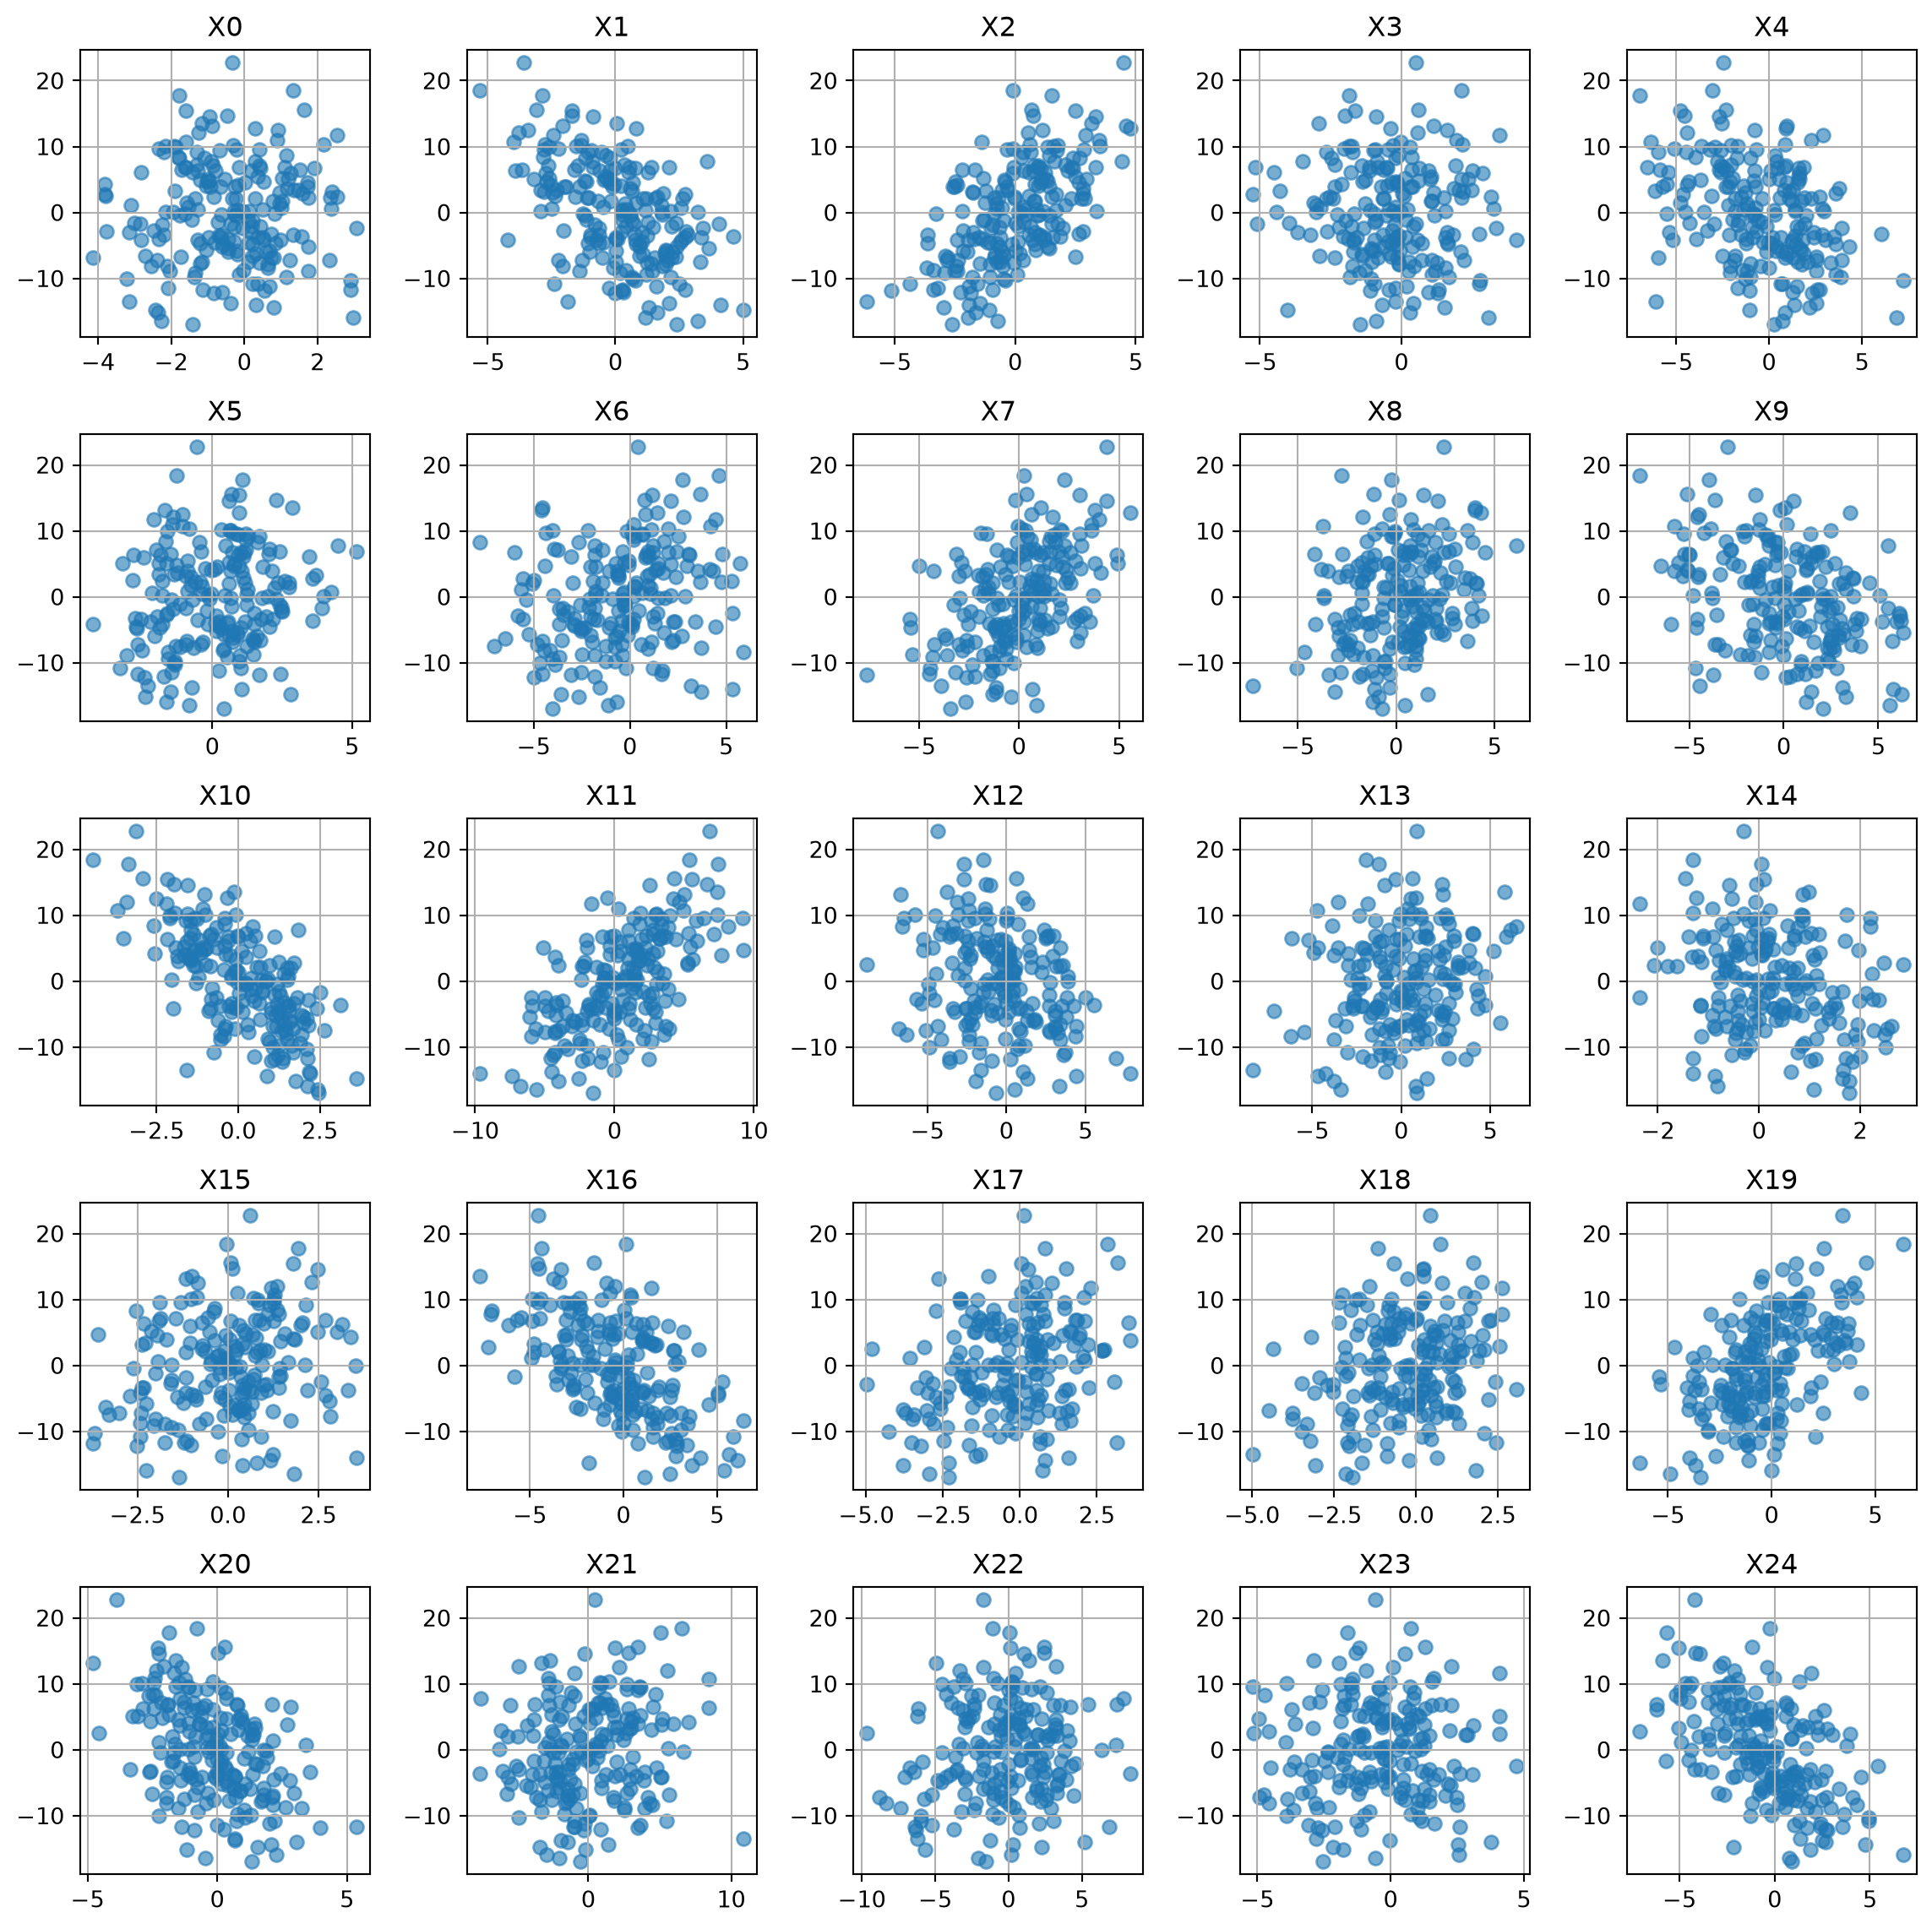

In [20]:
# Plot all of the features y as a function of Xn.
# Here I did not do SNS because we have 50 features and that is a lot!

fig, ax = plt.subplots(5, 5, figsize=(12, 12)) 
ax = ax.flatten()  # turn 2D array of axes into 1D list

for col, a in zip(x_cols, ax):
    a.scatter(df[col], df[y_cols], alpha=0.6)
    a.set_title(col)
    a.grid(True)

plt.tight_layout()
plt.show()

It seems like a linear regression might work here!

## Test Train VALIDATE split

As we get more advanced in our machine learning we are going to start doing a lot of hyperparameter tuning. When we tune we need a test set that technically our model gets to see during training (a part of the data set that helps us choose our parameters - before the official test at the end). This is the validation set!

- **Training Set** - used to fit/train the model and find the model parameters.
- **Validation Set** - used to check for over/undertraining and to select the best hyperparameters.
- **Testing Set** - used to truly test the model at the end.

In [21]:
# Test Train VALIDATE Split
X = df[x_cols]
y = df[y_cols]

random_seed = 42
# First split: hold out test data
X_train, X_test_full, y_train, y_test_full = train_test_split(
    X, y, test_size=0.2, random_state=random_seed
)

# Second split: create a validation set from the testing data
X_test, X_val, y_test, y_val = train_test_split(
    X_test_full, y_test_full, test_size=0.5, random_state=random_seed
)
# (Hold out data so that final proportions are 80% train / 10% val / 10% test)

print(f"Train: {len(X_train)}, Validation: {len(X_val)}, Test: {len(X_test)}")

Train: 160, Validation: 20, Test: 20


In [22]:
# Poly Features - choose the order of your polynomial
degree = 1
poly = PolynomialFeatures(degree=degree,include_bias=False)
X_train_poly = poly.fit_transform(X_train)
# transform the validation set
X_val_poly = poly.transform(X_val)


# Linear Regression
linreg = LinearRegression()
linreg.fit(X_train_poly, y_train)

# --- Get predictions Training ---
y_pred_train = linreg.predict(X_train_poly)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)
print(f"MSE on train set: {mse:.3f}")
print(f"R² on train set: {r2:.3f}")

# --- Get predictions Validation ---
y_pred_val = linreg.predict(X_val_poly)
mse = mean_squared_error(y_val, y_pred_val)
r2 = r2_score(y_val, y_pred_val)
print(f"MSE on val set: {mse:.3f}")
print(f"R² on val set: {r2:.3f}")

MSE on train set: 0.578
R² on train set: 0.990
MSE on val set: 1.757
R² on val set: 0.977


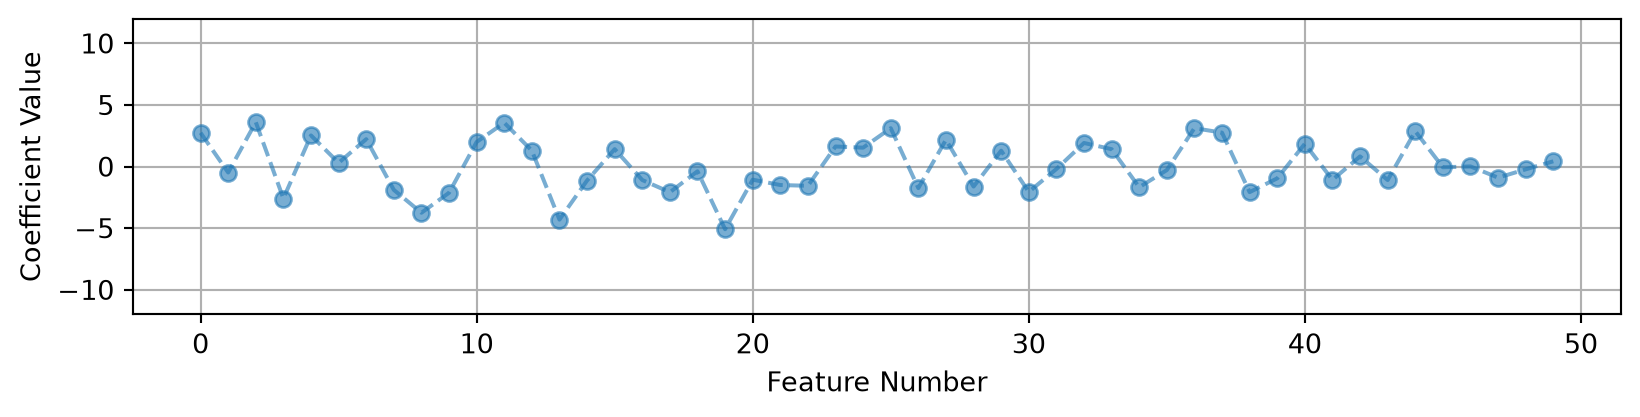

In [23]:
# Look at the magnitude of the coefficients
coef = linreg.coef_
coef_linreg_noscale = coef.reshape(-1)

x_pos = range(poly.n_output_features_)
plt.figure(figsize=(10,2))
plt.plot(x_pos, coef_linreg_noscale, '--o', alpha=.6)
plt.grid()
plt.ylim(-12,12)
plt.ylabel('Coefficient Value')
plt.xlabel('Feature Number')
plt.show()

## What Do We Notice?

We do really quite well on the training set! We have a small MSE and an $R^2$ close to 1. But when we look at the validation set our MSE goes up quite a bit. Our $R^2$ indicates that we are capturing most of the variance in the model, but we have significantly more error overall in the validation set (about 3 times the error!)

A more complicated model probably won't help, based on our good $R^2$ values, but we could try degree 2 or higher.


## Scaling or Normalizing the Data

One of the first things you should do in machine learning is scale your feature data. When your features have very different ranges for their maximum and minimum values this can really affect your model's ability to learn. You want to aim to have the values of your features be close to the range of $-1$ to $1$. 


### Look at our ranges:

In [24]:
# Look at the max and min values for each feature
pd.DataFrame(X_train,columns=x_cols).agg(['max', 'min'])

,X0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X40,X41,X42,X43,X44,X45,X46,X47,X48,X49
max,3.074681,5.015530,4.765435,4.072882,7.224084,5.173071,5.898216,5.549610,6.122514,6.221691,...,7.937595,7.118241,5.982261,9.164175,5.577571,3.636078,2.152546,5.413475,3.747611,3.173226
min,-4.127328,-4.210942,-6.158104,-5.234811,-6.943052,-4.255686,-7.784148,-7.611358,-7.250116,-5.981741,...,-8.198117,-7.866397,-7.156067,-7.745289,-5.472321,-2.761265,-2.012445,-4.458026,-5.212075,-3.735093


Notice how the some of the variables have very different ranges for their max and min. This is very bad for machine learning! If your variables have drastically different scales then features with large numerical ranges can cause problems. 

For example, when calculating distances in KNN - if some of your data had units of centimeters and went up to 10 and some of your data had units of dollars but went up to the millions - your distance calculations could be really skewed!

## Scale the Data

Often we scale our data so that it is closer to the range $[-1,1]$. Standard scalar is one way to do that:

**StandardScaler** rescales features to have:

$$
\text{mean} = 0, \quad \text{standard deviation} = 1
$$

For each feature $x$:

$$
x_{\text{scaled}} = \frac{x - \mu}{\sigma}
$$

where $\mu$ is the mean and $\sigma$ is the standard deviation of that feature.

**ALWAYS SCALE YOUR FEATURE DATA!!** From here on out, this should be a part of every model that you write with very few exceptions.

In [25]:
# New package: StandardScaler (we imported it at the top)

# Define the Scaler
scaler = StandardScaler()

# Find mu and sigma using your training data
# Also transform the training data
X_train_scaled = scaler.fit_transform(X_train)
# transform the validation set
X_val_scaled = scaler.transform(X_val)

In [26]:
# Look at the max and min values for each feature
pd.DataFrame(X_train_scaled,columns=x_cols).agg(['max', 'min'])

,X0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X40,X41,X42,X43,X44,X45,X46,X47,X48,X49
max,2.223363,2.609658,2.392681,2.360715,2.809527,2.798811,2.241920,2.420819,2.696811,2.045045,...,2.766322,2.885869,2.518609,2.527666,2.877369,2.64141,2.566428,2.343031,2.132623,2.324403
min,-2.438043,-2.364959,-3.109346,-2.635794,-2.444313,-2.434600,-2.594407,-3.308312,-3.343718,-2.128302,...,-2.872106,-3.294472,-2.688017,-2.405527,-2.812342,-2.36236,-2.199528,-2.086580,-2.545328,-2.427530


Now these are not exactly between positive and negative 1, but they are closer and much more consistent across variables!

Let's see if this helps our model:

In [27]:
# Redo the analysis

# Poly Features
degree = 1
poly = PolynomialFeatures(degree=degree,include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)
X_val_poly = poly.transform(X_val_scaled)

# Linear Regression
linreg = LinearRegression()
linreg.fit(X_train_poly, y_train)

# --- Get predictions Training ---
y_pred_train = linreg.predict(X_train_poly)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)
print(f"MSE on train set: {mse:.3f}")
print(f"R² on train set: {r2:.3f}")

# --- Get predictions Validation ---
y_pred_val = linreg.predict(X_val_poly)
mse = mean_squared_error(y_val, y_pred_val)
r2 = r2_score(y_val, y_pred_val)
print(f"MSE on val set: {mse:.3f}")
print(f"R² on val set: {r2:.3f}")

MSE on train set: 0.578
R² on train set: 0.990
MSE on val set: 1.757
R² on val set: 0.977


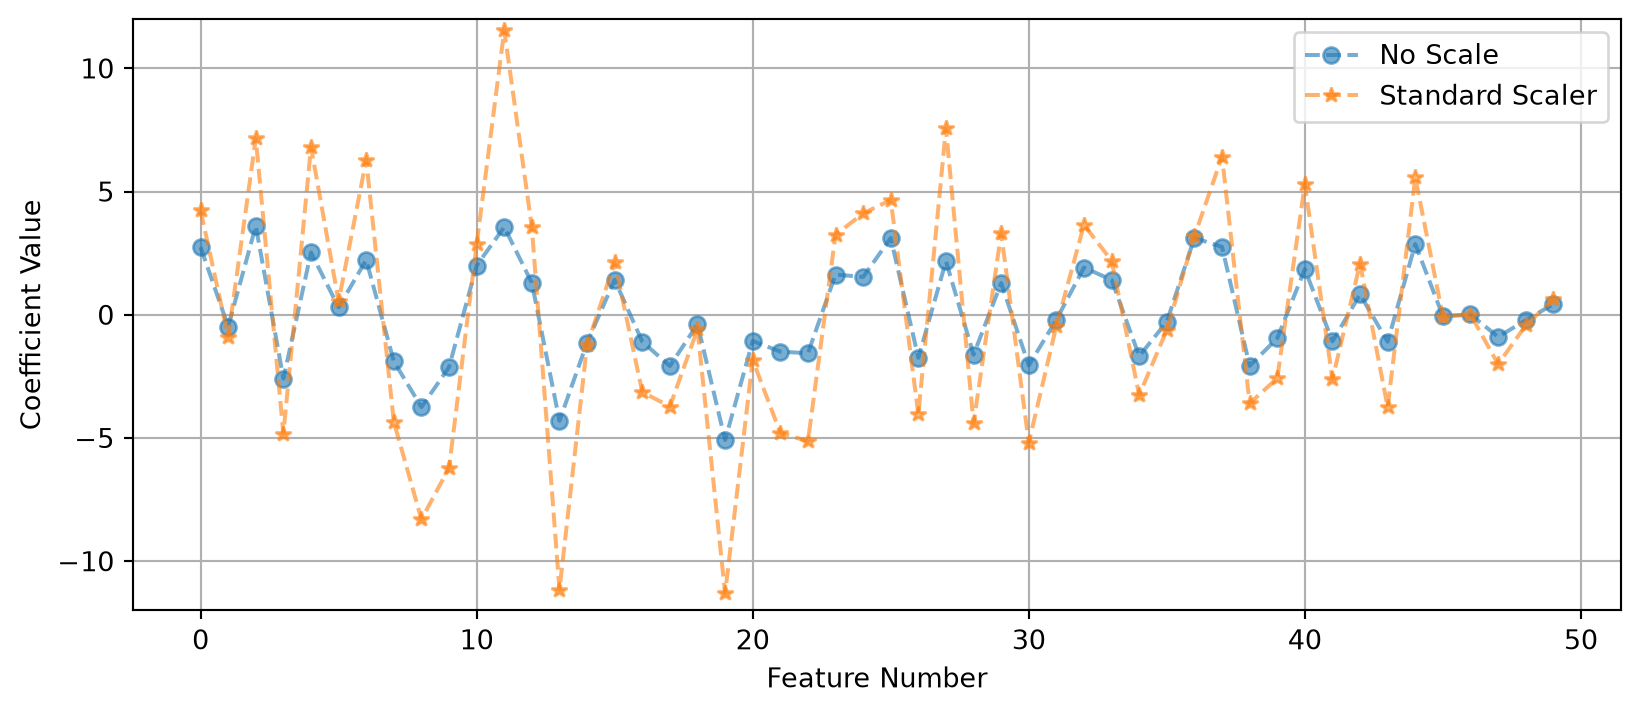

In [28]:
coef = linreg.coef_
coef_linreg_scale = coef.reshape(-1)

# Look at the magnitude of the coefficients

x_pos = range(poly.n_output_features_)
plt.figure(figsize=(10,4))
plt.plot(x_pos, coef_linreg_noscale, '--o', alpha=.6, label='No Scale')
plt.plot(x_pos, coef_linreg_scale, '--*', alpha=.6, label='Standard Scaler')
plt.grid()
plt.ylim(-12,12)
plt.ylabel('Coefficient Value')
plt.xlabel('Feature Number')
plt.legend()
plt.show()

In this case it did not do much for our MSE, because of the synthetic nature of the data... the variables were already on a similar range. But if you had some variables that were really large and some really small - then scaling the data is a MUST.

But we do see a change in the size of our coefficients. The overall size of the features changes the values of the coefficients. 

## Regularization

Regularization is a way to help stop your model from overfitting. Sometimes we see overfitting even when we have picked a very good model and it helps to add an extra penalty to the model to help it generalize better to new data.

Try changing to `degree = 2` in the code above. The training MSE goes all the way down to 0 and the validation MSE goes UP to about 4.5. So as we increase the polynomial we do better on the training data, but worse on the validation data. Our linear model (degree 1) was the best model, but it still overfits!

Why does this happen? In this case we are relying on a model that has poor feature selection. Too many features, or features that are highly correlated (this is called multicollinearity), and some features that don't really affect the model.


Let's consider the things that can go wrong in a model.


## Where does error come from

The Total Error in a model is the sum of three types of error:

$$ 
BIAS + VARIANCE + IRREDUCIBLE = TOTAL
$$

- Bias is the generalization error due to wrong assumptions and simplifications for your model. HIGH BIAS = underfit
- Variance is the error due to excessive sensitivity to small variations on the training data. HIGH VARIANCE = overfit
- Irreducible Error is the noisiness of the data itself.

Increasing a model's complexity will reduce the bias but increase the variance... there is always a trade-off here!

But what do we do if we are happy with our choice of polynomial or model but still see overfitting?

## Types of Regularization

Regularization helps to reduce overfitting and improves the generalizability of a model. It is almost always a good idea to add regularization to a model. 

There are many ways to do this. Today we will talk about three that work well whenever your model has linear coefficients.

**YOU MUST SCALE YOUR DATA BEFORE APPLYING REGULARIZATION**


## 1. Linear Regression (AKA Ordinary Least Squares (OLS))

Recall that linear regression minimizes the square error between predicted values and true values. We aim to minimize the loss in our model. Linear regression fits coefficients $b_0, b_1, ..., b_p$ by minimizing:

$$
\text{Loss} = \frac{1}{2n} \sum_{i=1}^{n} \left( y_i - \hat{y}_i \right)^2 
$$

where  

$$
\hat{y}_i = b_0 + b_1 x_{i1} + b_2 x_{i2} + \dots + b_p x_{ip} 
$$

This method finds coefficients that make the predicted values $\hat{y}_i$ as close as possible to the observed values $y_i$.

However, if you have many features or highly correlated ones, this can overfit, it may give large, unstable coefficients.

 
## 2. Ridge Regression (L2 Regularization)

Ridge regression adds a penalty on the **squared size** of the coefficients:

$$
\text{Loss} = \frac{1}{2n} \sum_{i=1}^{n} \left( y_i - \hat{y}_i \right)^2 + \alpha \sum_{j=1}^{p} b_j^2 
$$

The tuning parameter $\alpha$ controls how strong the penalty is:

- When $\alpha = 0$, this is just linear regression.
- When $\alpha$ is large, the coefficients shrink toward zero.

- Ridge keeps *all features* in the model (no coefficients become exactly zero).
- It helps when predictors are correlated.
- It works well when many variables each have small effects.

## 3. Lasso Regression (L1 Regularization)

Lasso regression adds a penalty on the **absolute values** of the coefficients:

$$
\text{Loss} = \frac{1}{2n} \sum_{i=1}^{n} \left( y_i - \hat{y}_i \right)^2 + \alpha \sum_{j=1}^{p} |b_j| 
$$

- Lasso can shrink some coefficients **exactly to zero**, effectively removing those features from the model.
- It performs **feature selection** automatically.
- It works well when only a few predictors are truly important (a "sparse" model).


## 4. Elastic Net (Combination of L1 and L2) - optional

This part is optional! Read it if you are curious, we will focus on Ridge and Lasso.

Elastic Net blends the Ridge and Lasso penalties:

$$
\text{Loss} = \frac{1}{2n} \sum_{i=1}^{n} \left( y_i - \hat{y}_i \right)^2
+ \alpha \left[L1 \sum_{j=1}^{p} |b_j| + (1 - L1) \sum_{j=1}^{p} b_j^2 \right]
$$

- $\alpha$ controls the overall strength of regularization.
- $L1$ controls the mix between Ridge (L2) and Lasso (L1):
  - $L1 = 1$ → Lasso
  - $L1 = 0$ → Ridge
  - $0 < L1 < 1$ → Elastic Net (a blend)

Elastic Net helps when you have many correlated predictors and still want some feature selection.

## Summary Table

| Model        | Penalty Term                      | Coefficients Become Zero? | Good For |
|---------------|-----------------------------------|----------------------------|-----------|
| Linear Regression (OLS)           | None                              | No                         | Baseline fitting |
| Ridge         | $\alpha \sum b_j^2$          | No                         | Multicollinearity |
| Lasso         | $\alpha \sum \lvert b_j \rvert$          | Yes                        | Feature selection |
| Elastic Net   | Mix of L1 and L2 penalties        | Some                       | Many correlated predictors |


 
Regularization adds a little bit of bias to our model, but it lowers the variance, so the model usually does better on new data.

- **Ridge** regression: Use when you think lots of features each have a small effect, or some of your features are correlated.  
- **Lasso** regression: Use when you think only a few features really matter and you want the model to drop the rest.  
- **Elastic Net**: Use when you want a bit of both: some coefficients set to zero, and stable coefficients when features are correlated.


Let's look at each of these!


Model Performance:


,MSE Train,MSE val,R² Train,R² val
Linear,0.578109,1.756675,0.989989,0.976960
Ridge (α=1),0.852579,1.152552,0.985236,0.984883
Lasso (α=0.1),0.894241,1.267345,0.984515,0.983378
"Elastic Net (α=1, mix=0.5)",2.806273,4.364667,0.951405,0.942754


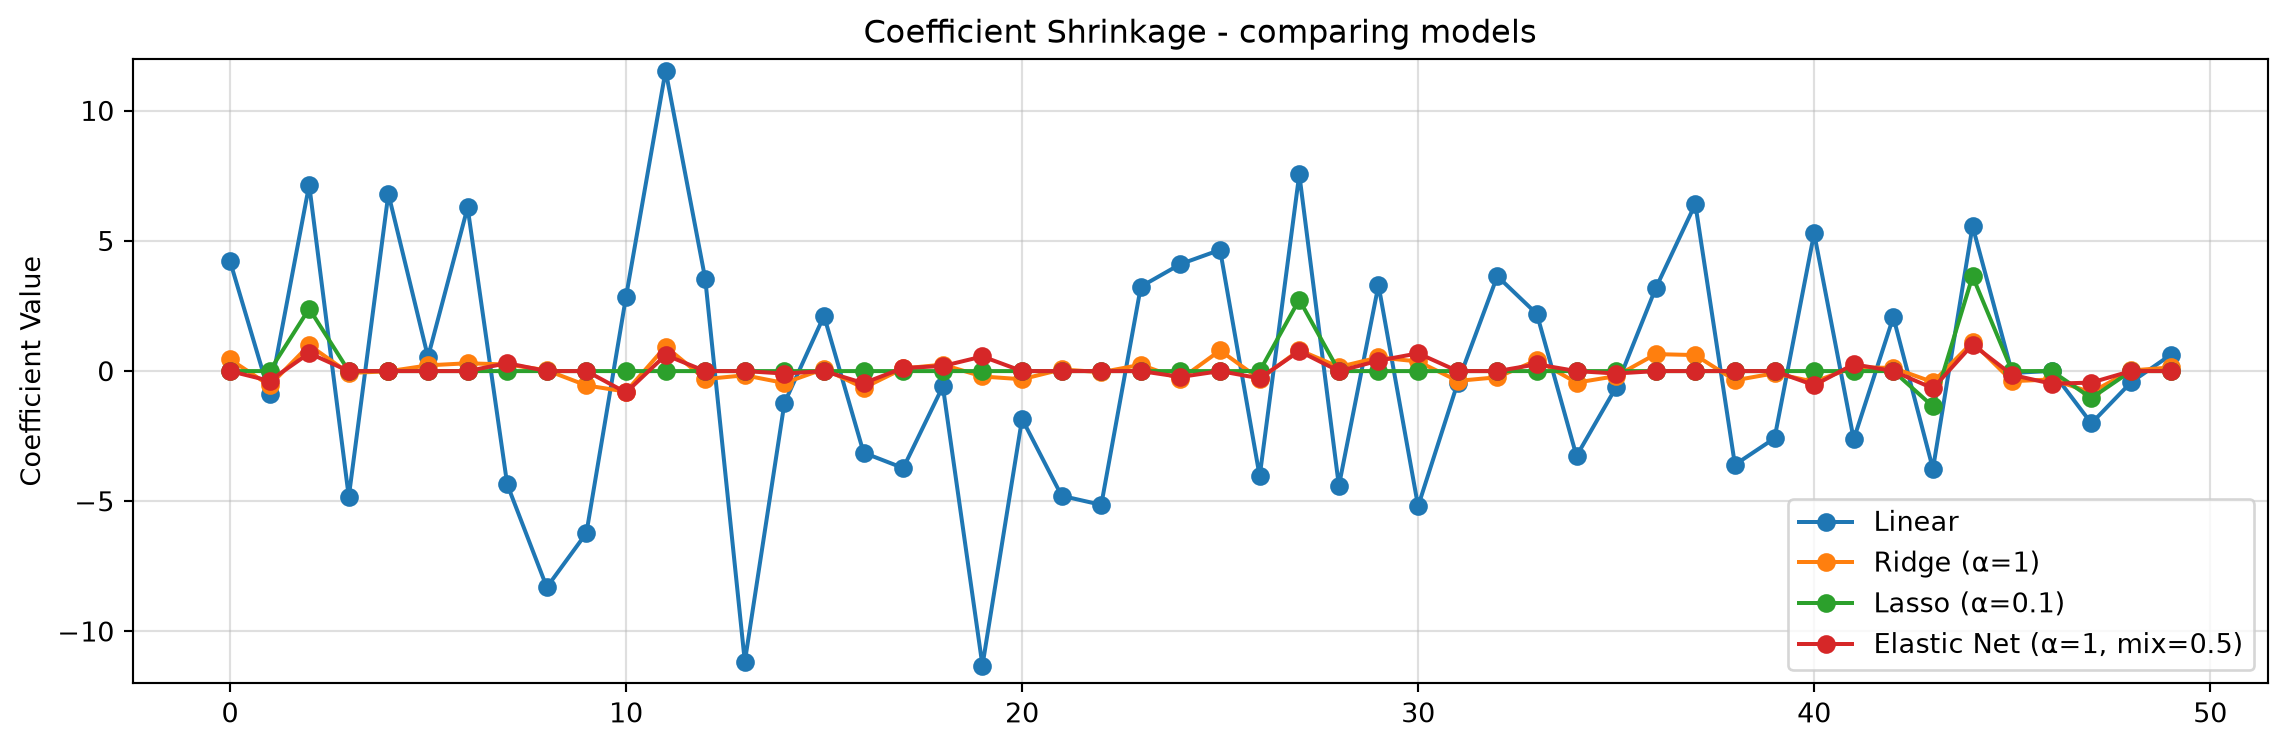

In [29]:
# Ridge, Lasso and ElasticNet were imported at the top

# Decide on polynomial features here we keep degree=1
degree = 1
poly = PolynomialFeatures(degree=degree,include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)
X_val_poly = poly.transform(X_val_scaled)


# Lets make a dictionary of each of the models I want to try
models = {
    "Linear": LinearRegression(),
    "Ridge (α=1)": Ridge(alpha=1),
    "Lasso (α=0.1)": Lasso(alpha=.1),
    "Elastic Net (α=1, mix=0.5)" : ElasticNet(alpha=1.0, l1_ratio=0.5)
}

# Some dictionaries to save the results
results = {}
coefs = {}

# Train each model
for name, model in models.items():
    model.fit(X_train_poly, y_train)
    y_pred_train = model.predict(X_train_poly)
    y_pred_val = model.predict(X_val_poly)
    # Save results for testing and training data
    results[name] = {
        "MSE Train": mean_squared_error(y_train, y_pred_train),
        "MSE val": mean_squared_error(y_val, y_pred_val),
        "R² Train": r2_score(y_train, y_pred_train),
        "R² val": r2_score(y_val, y_pred_val)
    }
    coefs[name] = model.coef_

# Compare the models
results_df = pd.DataFrame(results).T
print("\nModel Performance:")
display(results_df)

# Visualize the coefficient size
col_names = poly.get_feature_names_out(X.columns)
x_pos = np.arange(len(col_names))

plt.figure(figsize=(12,4))

for name, coef in coefs.items():
    plt.plot(x_pos, coef.reshape(-1), marker='o', label=name)

plt.title("Coefficient Shrinkage - comparing models")
plt.ylabel("Coefficient Value")
plt.ylim(-12,12)
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

## Observations

What we notice is that regularization reduces the size of the coefficients. In the data we see less overfitting, the MSE on training is closer to what we see on the validation set and we have not hurt our $R^2$ values. This means that our model is more likely to generalize to new data.

We now have more hyperparameters! We have to decide on values for $\alpha$ and in the case of elastic net $L1$. How do we figure out what value of alpha to use?

## Searching for Alpha - Ridge

Let's do an example of finding alpha values for our ridge regression


Model Performance:


,MSE Train,MSE Val,R² Train,R² Val
alpha = 0.0,0.578109,1.756675,0.989989,0.976960
alpha = 0.1,0.703788,1.246276,0.987813,0.983654
alpha = 0.2,0.757307,1.189517,0.986886,0.984398
alpha = 0.30000000000000004,0.786855,1.169877,0.986374,0.984656
alpha = 0.4,0.805903,1.161131,0.986045,0.984771
...,...,...,...,...
alpha = 49.5,0.980071,1.437672,0.983029,0.981144
alpha = 49.6,0.980387,1.438457,0.983023,0.981133
alpha = 49.7,0.980705,1.439242,0.983018,0.981123
alpha = 49.800000000000004,0.981023,1.440028,0.983012,0.981113


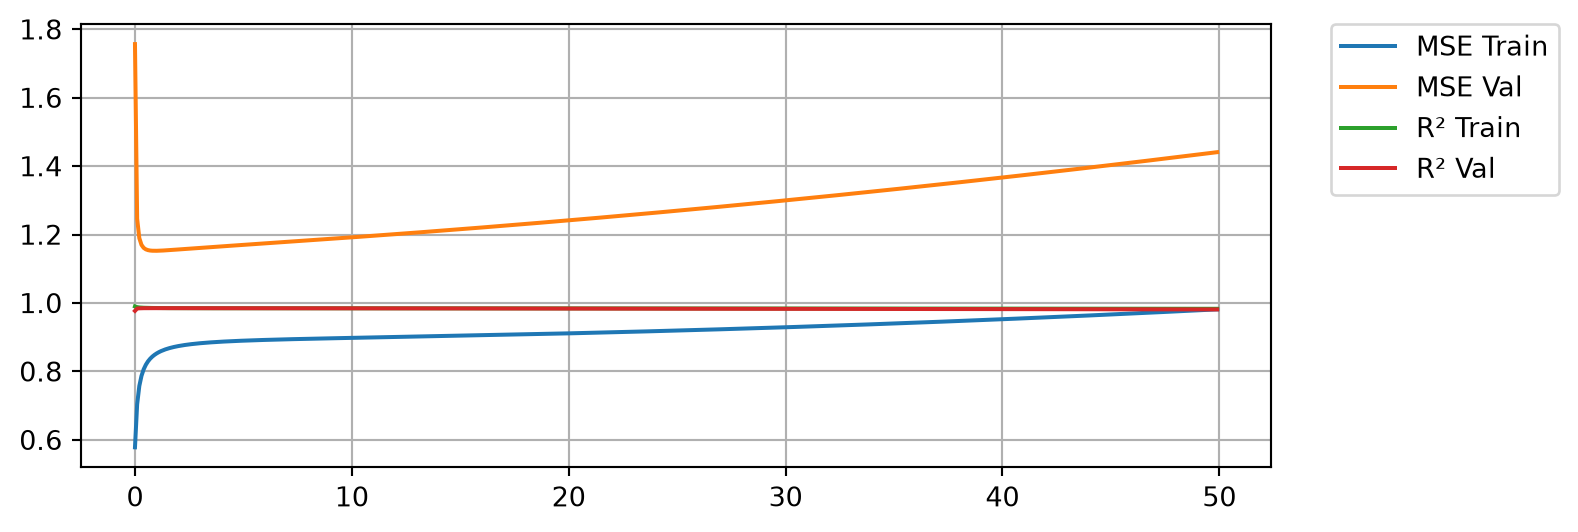

In [30]:
alpha_vals = np.arange(0,50,.1)
results = {}

for a in alpha_vals:

    if a == 0:
        model = LinearRegression()
    else:
        model = Ridge(alpha=a)
    model.fit(X_train_poly, y_train)

    y_pred_train = model.predict(X_train_poly)
    y_pred_val = model.predict(X_val_poly)
    results[f"alpha = {a}"] = {
        "MSE Train": mean_squared_error(y_train, y_pred_train),
        "MSE Val": mean_squared_error(y_val, y_pred_val),
        "R² Train": r2_score(y_train, y_pred_train),
        "R² Val": r2_score(y_val, y_pred_val)
    }

results_df = pd.DataFrame(results).T
print("\nModel Performance:")
display(results_df)

plt.figure(figsize=(8,3))
for c in results_df.keys():
    plt.plot(alpha_vals,results_df[c],label=c)

#plt.xticks(alpha_vals)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.grid()
plt.show()

Here we see that with no regularization we do very well on the training MSE but significantly worse on the validation MSE. In both cases we are capturing the variance in the data as shown by our $R^2$ values being close to 1. A little bit of regularization goes a long way. We see that as we add regularization, we start to do better and better on the validation MSE, but only for a while. As we keep increasing regularization we start to do worse again on the validation data, so we are looking for an $\alpha$ that gives us the best results on the validation data.

In [31]:
min_MSE = 1000
for a in results.keys():
    mse_val = results[a]['MSE Val']
    if mse_val < min_MSE:
        min_MSE = mse_val
        best_alpha = a

print(f'Min MSE on validation set was {min_MSE} with an alpha of {best_alpha}')

Min MSE on validation set was 1.1525184994940274 with an alpha of alpha = 0.9


## Searching for Alpha - Lasso

Let's do an example of finding alpha values for our lasso regression


Model Performance:


,MSE Train,MSE val,R² Train,R² val
alpha = 0.0,0.578109,1.756675,0.989989,0.976960
alpha = 0.05,0.875297,1.224568,0.984843,0.983939
alpha = 0.1,0.894241,1.267345,0.984515,0.983378
alpha = 0.15000000000000002,0.924844,1.325755,0.983985,0.982612
alpha = 0.2,0.967675,1.398712,0.983243,0.981655
alpha = 0.25,1.022748,1.486174,0.982290,0.980508
alpha = 0.30000000000000004,1.091776,1.577950,0.981094,0.979304
alpha = 0.35000000000000003,1.173528,1.682930,0.979679,0.977927
alpha = 0.4,1.267808,1.802420,0.978046,0.976360
alpha = 0.45,1.372751,1.943044,0.976229,0.974515


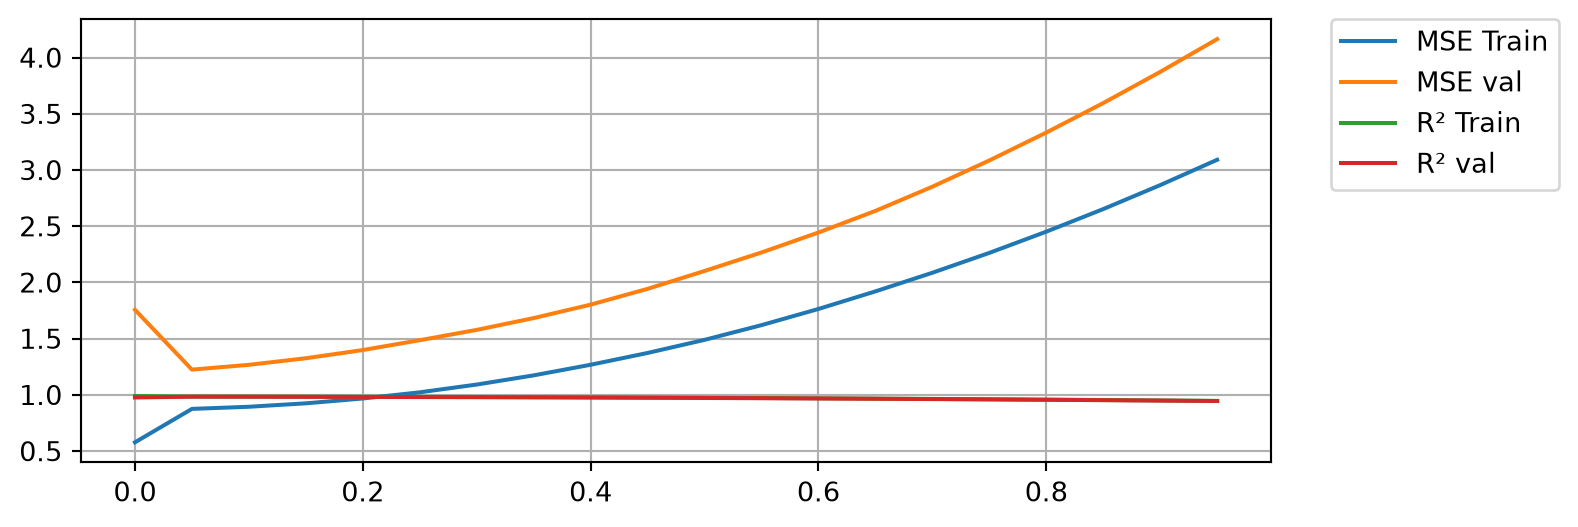

In [32]:
alpha_vals = np.arange(0,1,.05)
results = {}

for a in alpha_vals:
    if a == 0:
        model = LinearRegression()
    else:    
        model = Lasso(alpha=a,max_iter=10000)
    model.fit(X_train_poly, y_train)

    y_pred_train = model.predict(X_train_poly)
    y_pred_val = model.predict(X_val_poly)
    results[f"alpha = {a}"] = {
        "MSE Train": mean_squared_error(y_train, y_pred_train),
        "MSE val": mean_squared_error(y_val, y_pred_val),
        "R² Train": r2_score(y_train, y_pred_train),
        "R² val": r2_score(y_val, y_pred_val)
    }

results_df = pd.DataFrame(results).T
print("\nModel Performance:")
display(results_df)

plt.figure(figsize=(8,3))
for c in results_df.keys():
    plt.plot(alpha_vals,results_df[c],label=c)

#plt.xticks(alpha_vals)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.grid()
plt.show()

In [33]:
min_MSE = 1000
for a in results.keys():
    mse_val = results[a]['MSE val']
    if mse_val < min_MSE:
        min_MSE = mse_val
        best_alpha = a

print(f'Min MSE on validation set was {min_MSE} with an alpha of {best_alpha}')

Min MSE on validation set was 1.2245683950321085 with an alpha of alpha = 0.05


Again we see regularization improve the results at first. Notice how Lasso is more sensitive to the alpha value! We also see how too much Lasso hurts the training results too.

## You Try (optional)

Write a loop to do a parameter search for Elastic net. You will need to do a double for loop and search through two sets of parameters: $\alpha$ and $L1$. 

## Other Considerations

For all of the analysis above we assumed degree = 1 for our polynomial. It might be worth rerunning the code above to see if we could get better results with a higher degree polynomial.

## Now test the model

Once you choose an alpha value for your regularization and you are fairly certain that you have the best possible model for your goals, then you are ready to see how you do on the testing set.

**This is the actual model that you report - your final results!** Everything above is important to do and talk about (eg. show some plots), but your results is the final best model you could train and it's performance on the testing set.

In [34]:
alpha = .9
degree = 1

# Do ALL THE SAME PREPROCESSING STEPS!
# Scale the Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
# Feature Engineering - polynomials
poly = PolynomialFeatures(degree=degree,include_bias=False)
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)


# Train the model
model = Ridge(alpha=alpha)
model.fit(X_train_poly, y_train)

# Get the training results
y_pred_train = model.predict(X_train_poly)
mse = mean_squared_error(y_train, y_pred_train)
r2 = r2_score(y_train, y_pred_train)
print(f"MSE on train set: {mse:.3f}")
print(f"R² on train set: {r2:.3f}")

# Get the testing results
y_pred_test = model.predict(X_test_poly)
mse = mean_squared_error(y_test, y_pred_test)
r2 = r2_score(y_test, y_pred_test)
print(f"MSE on test set: {mse:.3f}")
print(f"R² on test set: {r2:.3f}")

MSE on train set: 0.848
R² on train set: 0.985
MSE on test set: 1.739
R² on test set: 0.958


---------------------------------------

## Homework 13

The full assignment is in `HW_day13.ipynb` in your sandbox. You will analyze the WHO life expectancy data, pick a model and explain why, and then see if scaling and regularization help your linear model do better on new data.

Work the problems in your sandbox and push it, your sandbox is your backup. Your write-up notebook goes in `Week08` of your team's repo, along with Homework 14. Both are due **Sunday 11/8 at 11:59pm**.